In [1]:
import os, sys
from pathlib import Path

import xarray as xr
import matplotlib.pyplot as plt

In [35]:
ESMEVAL = Path("/gws/ssde/j25a/esmeval/obsdata-v2")

paths = {
    # Observations
    "HadCRUT4":       Path("/badc/ukmo-hadobs/data/insitu/MOHC/HadOBS/HadCRUT4/"),
    # hadcrut5 is better
    "BerkeleyEarth":  Path(f"{ESMEVAL}/Tier2/BerkeleyEarth/"),
    "GISTEMP":        Path(f"{ESMEVAL}/Tier2/GISTEMP/"),
    "NOAAGlobalTemp": Path(f"{ESMEVAL}/Tier2/NOAAGlobalTemp/"),
    # Reanalyses
    "ERA5_hourly":    Path("/badc/ecmwf-era5/data/oper/an_sfc/"),
    "ERA5":           Path(f"{ESMEVAL}/Tier3/ERA5/"),
    "CFSR":           Path(f"{ESMEVAL}/Tier2/CFSR/"),
    "MERRA2":         Path(f"{ESMEVAL}/Tier3/MERRA2/"),
    "JRA55":          Path(f"{ESMEVAL}/Tier1/JRA-55/"),
    "CRA40":          None,  # not on JASMIN
}

## RECON

In [75]:
import shutil
from importlib import reload

In [76]:
# source_path = Path('/home/users/aborow/recon_t2m_1958-2025_ano.final.nc')
# destination_path = Path('/gws/ssde/j25a/extant/users/aborow')
# shutil.move(source_path, destination_path / source_path.name)

In [77]:
import src.paths

In [78]:
reload(src.paths)

<module 'src.paths' from '/home/users/aborow/ExtAnt-initial/drafts/../src/paths.py'>

In [79]:
src.paths.RECON_PATH

PosixPath('/gws/ssde/j25a/extant/users/aborow/recon_t2m_1958-2025_ano.final.nc')

In [80]:
recon_da = xr.open_dataset(src.paths.RECON_PATH)

In [81]:
recon_da

<xarray.Dataset> Size: 43MB
Dimensions:   (time: 816, south_north: 114, west_east: 114)
Coordinates:
  * time      (time) datetime64[ns] 7kB 1958-01-01 1958-02-01 ... 2025-12-01
    lat       (south_north, west_east) float32 52kB ...
    lon       (south_north, west_east) float32 52kB ...
Dimensions without coordinates: south_north, west_east
Data variables:
    RECON     (time, south_north, west_east) float32 42MB ...
    HGT       (south_north, west_east) float32 52kB ...
    LANDMASK  (south_north, west_east) float32 52kB ...
Attributes: (12/15)
    title:        Antarctica Temperature Reconstruction
    GRIDTYPE:     C
    DX:           60000.0
    DY:           60000.0
    CEN_LAT:      -90.0
    CEN_LON:      0.0
    ...           ...
    MAP_PROJ:     2
    Note1:        MAP_PROJ = 2 : WRF Polar Stereography/polar
    Note2:        GRID OUTPUT FROM WPS GEOGRID V4.1
    Institute_1:  The Ohio State University
    Institute_2:  Byrd Polar and Climate Research Center
    Institute_3:  Polar Meteorology Group

In [87]:
recon_da.attrs

{'title': 'Antarctica Temperature Reconstruction',
 'GRIDTYPE': 'C',
 'DX': np.float32(60000.0),
 'DY': np.float32(60000.0),
 'CEN_LAT': np.float32(-90.0),
 'CEN_LON': np.float32(0.0),
 'TRUELAT1': np.float32(-60.1),
 'TRUELAT2': np.float32(-60.0),
 'STAND_LON': np.float32(0.0),
 'MAP_PROJ': np.int32(2),
 'Note1': 'MAP_PROJ = 2 : WRF Polar Stereography/polar',
 'Note2': 'GRID OUTPUT FROM WPS GEOGRID V4.1',
 'Institute_1': 'The Ohio State University',
 'Institute_2': 'Byrd Polar and Climate Research Center',
 'Institute_3': 'Polar Meteorology Group'}

In [82]:
recon_da.RECON.attrs

{'units': 'K', 'long_name': 'Near-surface temperature anomaly'}

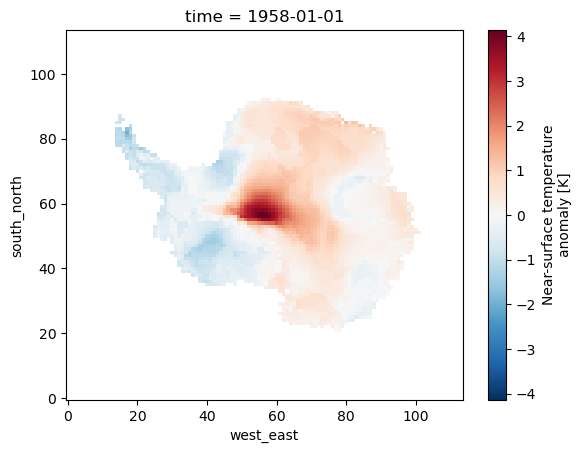

In [86]:
recon_da.RECON.isel(time=0).plot()

In [92]:
recon_da.lon.values.shape

(114, 114)

In [90]:
recon_da.lat.values.shape

(114, 114)

## JRA-55

In [44]:
np.sort(list((Path('/badc')).iterdir()))[0]

PosixPath('/badc/.fileset_info.json')

In [1]:
# np.sort(list((Path('/badc')).iterdir()))

In [45]:
[p for p in np.sort(list((Path('/badc')).iterdir())) if 'jra' in str(p)]

[]

In [38]:
list((ESMEVAL / 'Tier3').iterdir())

[PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier3/ERA-Interim-Land'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier3/ERA-Interim'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier3/ERA5'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier3/FLUXCOM')]

In [37]:
jra55_paths = list((paths["JRA55"]).iterdir())
jra55_paths

[PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier1/JRA-55/clt_Amon_reanalysis_JRA-55_195801-201912.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier1/JRA-55/pr_Amon_reanalysis_JRA-55_195801-201912.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier1/JRA-55/psl_Amon_reanalysis_JRA-55_195801-201312.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier1/JRA-55/psl_Amon_reanalysis_JRA-55_201401-201412.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier1/JRA-55/psl_Amon_reanalysis_JRA-55_201501-201512.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier1/JRA-55/psl_Amon_reanalysis_JRA-55_201601-201603.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier1/JRA-55/rldscs_Amon_reanalysis_JRA-55_195801-201312.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier1/JRA-55/rlut_Amon_reanalysis_JRA-55_195801-201312.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier1/JRA-55/rlut_Amon_reanalysis_JRA-55_195801-201912.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata

## Berkley

In [3]:
berkely_paths = list((paths["BerkeleyEarth"]).iterdir())
berkely_paths

[PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier2/BerkeleyEarth/OBS_BerkeleyEarth_reanaly_2020_Amon_tas_185001-201912.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier2/BerkeleyEarth/OBS_BerkeleyEarth_reanaly_2020_Amon_tasa_185001-201912.nc'),
 PosixPath('/gws/ssde/j25a/esmeval/obsdata-v2/Tier2/BerkeleyEarth/OBS_BerkeleyEarth_reanaly_2020_fx_sftlf.nc')]

In [4]:
berkely_ds = (
    xr.open_dataset('/gws/ssde/j25a/esmeval/obsdata-v2/Tier2/BerkeleyEarth/OBS_BerkeleyEarth_reanaly_2020_Amon_tas_185001-201912.nc')
    .tas
    .drop_vars('height')
             )

In [5]:
larsen_c = {"lat": -67.5,"lon": -62.5}


In [6]:
import os, sys

In [7]:
sys.path.append('../')

In [8]:
from extant.plots import antarctica

In [9]:
antarctica.style_antarctic_ax

<function extant.plots.antarctica.style_antarctic_ax(ax, add_lat_lon: bool = False)>

In [10]:
import numpy as np

In [ ]:
berkely_ds.sel(time=)

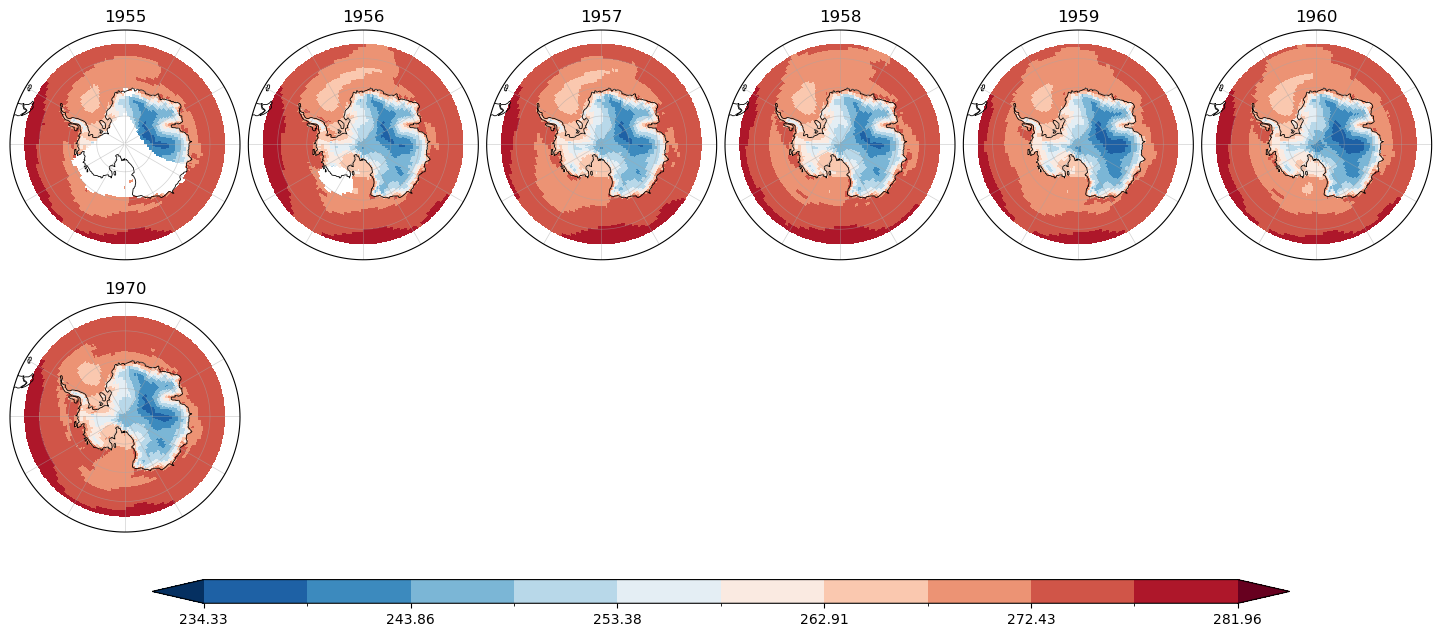

In [20]:
# i_times = [0, 10, 100, 1000, 1500, 2000, -1]
years = [1955, 1956, 1957, 1958, 1959, 1960, 1970, 1980, 1990, 2000, 2010]


# berkely_times_da = berkely_ds.sel(lat=slice(None, -75)).isel(time=i_times)
t = berkely_ds.time.dt
berkely_times_da = berkely_ds.sel(
    lat=slice(None, -55),
    time=t.year.isin(years) & (t.month == 1),
)

n_rows = 2
n_cols = int(np.ceil(berkely_times_da.sizes['time']/ n_rows))


fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=n_rows, n_cols=n_cols, n_colorbar_rows=1),
                 layout='constrained')

axes = antarctica.map_axes(fig, n_rows=n_rows, n_cols=n_cols)
cax = antarctica.colorbar_axis_below(axes)

time_axes = np.ravel(axes)[:berkely_times_da.sizes['time']]
antarctica.heatmaps_of_antarctica(berkely_times_da, 'time', None, axes=time_axes, cax=cax)

# After the heatmaps, which clear each map's title
for ax, time in zip(time_axes, berkely_times_da['time'].dt.year.values):
    ax.set_title(time)
for ax in np.ravel(axes)[len(i_times):]:
    ax.set_visible(False)

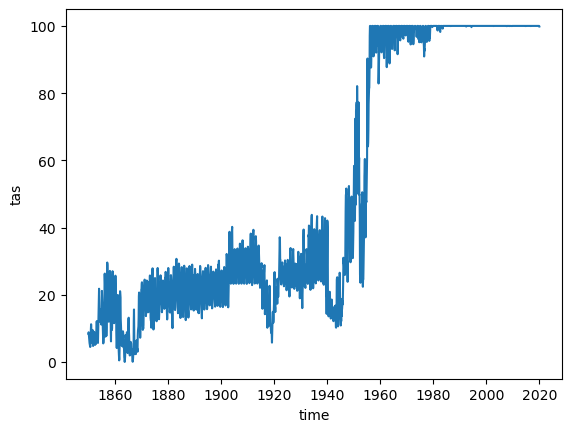

In [25]:
(berkely_ds.sel(
    lat=slice(None, -55)).notnull().mean(dim=['lat', 'lon']) * 100).plot()

## HadCRUT

In [26]:
list((paths["HadCRUT4"]/'mon'/'HadCRUT4Table').iterdir())[:5]

[PosixPath('/badc/ukmo-hadobs/data/insitu/MOHC/HadOBS/HadCRUT4/mon/HadCRUT4Table/r24'),
 PosixPath('/badc/ukmo-hadobs/data/insitu/MOHC/HadOBS/HadCRUT4/mon/HadCRUT4Table/r42'),
 PosixPath('/badc/ukmo-hadobs/data/insitu/MOHC/HadOBS/HadCRUT4/mon/HadCRUT4Table/r60'),
 PosixPath('/badc/ukmo-hadobs/data/insitu/MOHC/HadOBS/HadCRUT4/mon/HadCRUT4Table/r23'),
 PosixPath('/badc/ukmo-hadobs/data/insitu/MOHC/HadOBS/HadCRUT4/mon/HadCRUT4Table/r41')]

In [6]:
list((paths["HadCRUT4"]/'mon'/'HadCRUT4Table'/'r24'/'HadCRUT-4-4-0-0'/'v20160331'/'tas').iterdir())

[PosixPath('/badc/ukmo-hadobs/data/insitu/MOHC/HadOBS/HadCRUT4/mon/HadCRUT4Table/r24/HadCRUT-4-4-0-0/v20160331/tas/tas_HadCRUT4_HadOBS_r24_HadCRUT-4-4-0-0_18500101-20160331.nc')]

In [7]:
p1 = '/badc/ukmo-hadobs/data/insitu/MOHC/HadOBS/HadCRUT4/mon/HadCRUT4Table/r24'

In [8]:
ds = xr.open_dataset(p1)

ValueError: did not find a match in any of xarray's currently installed IO backends ['netcdf4', 'h5netcdf', 'scipy', 'CFA', 'cfgrib', 'gini', 'kerchunk', 'pydap', 'rasterio', 'zarr']. Consider explicitly selecting one of the installed engines via the ``engine`` parameter, or installing additional IO dependencies, see:
https://docs.xarray.dev/en/stable/getting-started-guide/installing.html
https://docs.xarray.dev/en/stable/user-guide/io.html

In [ ]:
ds